# 03 Clasificador Baseline

## Objetivo

Entrenar y evaluar tres clasificadores baseline sobre SpaPhish para establecer
una línea de referencia antes de explorar modelos más complejos.

Los modelos evaluados son:
- TF-IDF + Logistic Regression
- TF-IDF + SVM (LinearSVC)
- TF-IDF + Random Forest

## Consideraciones

- No se muestran mensajes originales ni contenido sensible en las salidas.
- El split es reproducible con seed fija (`RANDOM_STATE = 42`).
- La métrica principal es el **recall de la clase phishing** (objetivo ≥ 95%).
- Las anotaciones manuales de ingeniería social no se usan como predictores
  (no estarían disponibles para un correo nuevo).

## 0. Imports y configuración

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
)
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
RECALL_TARGET = 0.95

## 1. Carga del dataset

In [2]:
PROJECT_ROOT = Path.cwd()

if (PROJECT_ROOT / "ml" / "data" / "raw").exists():
    DATA_DIR = PROJECT_ROOT / "ml" / "data" / "raw"
elif (PROJECT_ROOT.parent / "data" / "raw").exists():
    DATA_DIR = PROJECT_ROOT.parent / "data" / "raw"
else:
    raise FileNotFoundError("Dataset directory not found.")

SPAPHISH_PATH = DATA_DIR / "spaphish" / "Spaphish dataset - DiB.csv"

if not SPAPHISH_PATH.exists():
    raise FileNotFoundError(f"SpaPhish not found: {SPAPHISH_PATH}")

raw = pd.read_csv(SPAPHISH_PATH, sep=",", encoding="utf-8", on_bad_lines="error")
print(f"Dataset cargado: {raw.shape[0]} filas, {raw.shape[1]} columnas")
print(f"Distribución de clases:\n{raw['Label'].value_counts()}")

Dataset cargado: 1395 filas, 47 columnas
Distribución de clases:
Label
1    731
0    664
Name: count, dtype: int64


## 2. Preprocesamiento (#34)

Limpieza mínima según las recomendaciones del EDA:
- Combinar asunto y cuerpo en un único campo de texto.
- Tratar asuntos vacíos como cadena vacía.
- Eliminar duplicados exactos.
- No usar anotaciones manuales como predictores.

### 2.1. Anonimización, Placeholder NER (#37)

En producción el backend entrega el texto ya anonimizado antes de llamar al clasificador.
Para que el entrenamiento reproduzca esa misma distribución, aplicamos aquí una
anonimización basada en expresiones regulares como placeholder provisional.
La issue #37 sustituirá estas reglas por un modelo NER; los tokens de reemplazo
(`[EMAIL]`, `[URL]`, `[IBAN]`, `[PHONE]`) serán idénticos en ambas versiones.

In [3]:
_ANON_PATTERNS = [
    # URLs antes que emails para evitar match parcial
    (re.compile(r"https?://\S+", re.IGNORECASE), "[URL]"),
    (re.compile(r"\b[\w.+-]+@[\w-]+\.[a-z]{2,}\b", re.IGNORECASE), "[EMAIL]"),
    # IBANs (formato ES/EU)
    (re.compile(r"\b[A-Z]{2}\d{2}[\s]?(?:\d{4}[\s]?){3,6}\b"), "[IBAN]"),
    # Teléfonos españoles e internacionales
    (re.compile(r"\b(?:\+?34[\s\-]?)?[6789]\d{2}[\s\-]?\d{3}[\s\-]?\d{3}\b"), "[PHONE]"),
]

def anonymize(text: str) -> str:
    for pattern, placeholder in _ANON_PATTERNS:
        text = pattern.sub(placeholder, text)
    return text


df = raw.copy()

# Anonimizar cada columna por separado (body queda listo para el experimento SMS)
df["subject"] = df["subject"].fillna("").apply(anonymize)
df["body"]    = df["body"].fillna("").apply(anonymize)

# Combinar para el baseline email
df["text"] = (df["subject"] + " " + df["body"]).str.strip()

# Eliminar duplicados exactos de texto combinado
before = len(df)
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
print(f"Duplicados eliminados: {before - len(df)}")
print(f"Registros tras limpieza: {len(df)}")
print("Anonimización aplicada (regex placeholder para NER #37)")
print(f"Distribución de clases:\n{df['Label'].value_counts()}")

Duplicados eliminados: 2
Registros tras limpieza: 1393
Anonimización aplicada (regex placeholder para NER #37)
Distribución de clases:
Label
1    729
0    664
Name: count, dtype: int64


## 3. Split train / validation / test

Split 70 / 15 / 15 con seed fija y estratificación por clase.

In [4]:
X = df["text"]
y = df["Label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Distribución train:\n{y_train.value_counts()}")

Train: 975 | Val: 209 | Test: 209
Distribución train:
Label
1    510
0    465
Name: count, dtype: int64


## 4. Entrenamiento de los tres modelos baseline

In [5]:
pipelines = {
    "LR": Pipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, max_features=50_000)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "SVM": Pipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, max_features=50_000)),
        ("clf", LinearSVC(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "RF": Pipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, max_features=50_000)),
        ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    ]),
}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} entrenado.")

LR entrenado.
SVM entrenado.
RF entrenado.


## 5. Evaluación en validación

In [6]:
results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_val)
    recall_phishing = recall_score(y_val, y_pred, pos_label=1)
    report = classification_report(y_val, y_pred, target_names=["legítimo", "phishing"], output_dict=True)
    results.append({
        "modelo": name,
        "precision_phishing": report["phishing"]["precision"],
        "recall_phishing": report["phishing"]["recall"],
        "f1_phishing": report["phishing"]["f1-score"],
        "precision_legitimo": report["legítimo"]["precision"],
        "recall_legitimo": report["legítimo"]["recall"],
        "f1_legitimo": report["legítimo"]["f1-score"],
        "accuracy": report["accuracy"],
        "cumple_objetivo": recall_phishing >= RECALL_TARGET,
    })
    print(f"\n── {name} ──")
    print(classification_report(y_val, y_pred, target_names=["legítimo", "phishing"]))

results_df = pd.DataFrame(results)
display(results_df.round(3))


── LR ──
              precision    recall  f1-score   support

    legítimo       0.90      0.96      0.93        99
    phishing       0.96      0.91      0.93       110

    accuracy                           0.93       209
   macro avg       0.93      0.93      0.93       209
weighted avg       0.93      0.93      0.93       209


── SVM ──
              precision    recall  f1-score   support

    legítimo       0.97      0.98      0.97        99
    phishing       0.98      0.97      0.98       110

    accuracy                           0.98       209
   macro avg       0.98      0.98      0.98       209
weighted avg       0.98      0.98      0.98       209


── RF ──
              precision    recall  f1-score   support

    legítimo       0.94      0.85      0.89        99
    phishing       0.88      0.95      0.91       110

    accuracy                           0.90       209
   macro avg       0.91      0.90      0.90       209
weighted avg       0.91      0.90      0.90

,modelo,precision_phishing,recall_phishing,f1_phishing,precision_legitimo,recall_legitimo,f1_legitimo,accuracy,cumple_objetivo
0,LR,0.962,0.909,0.935,0.905,0.960,0.931,0.933,False
1,SVM,0.982,0.973,0.977,0.970,0.980,0.975,0.976,True
2,RF,0.875,0.955,0.913,0.944,0.848,0.894,0.904,True


## 6. Matrices de confusión

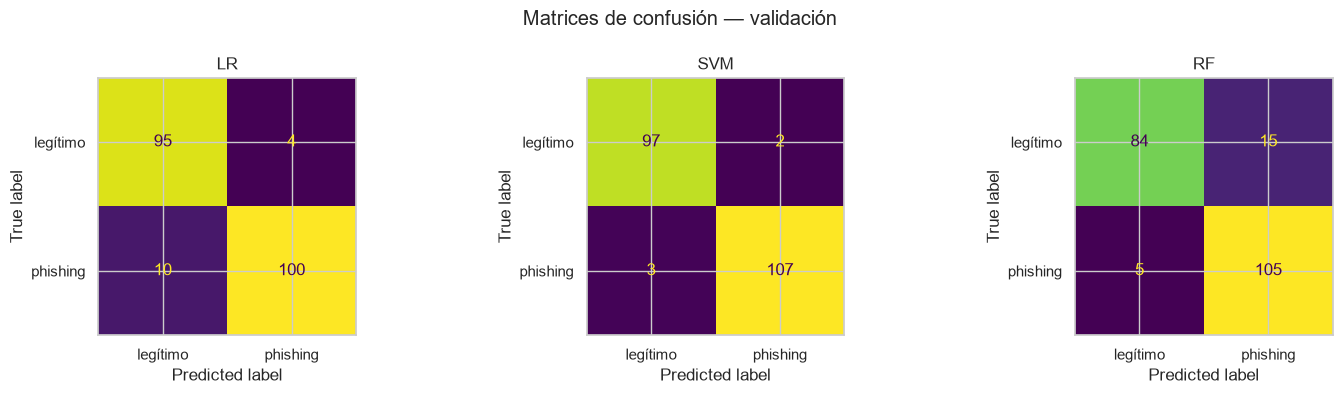

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, pipelines.items()):
    y_pred = pipeline.predict(X_val)
    cm = confusion_matrix(y_val, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["legítimo", "phishing"])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.suptitle("Matrices de confusión — validación")
plt.tight_layout()
plt.show()

## 7. Comparativa de recall (objetivo ≥ 95%)

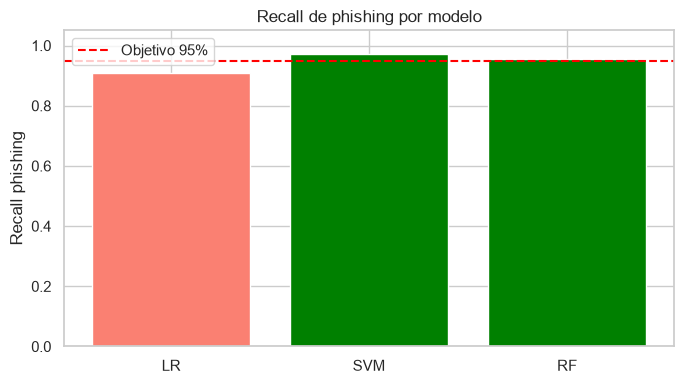

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["green" if v >= RECALL_TARGET else "salmon" for v in results_df["recall_phishing"]]
ax.bar(results_df["modelo"], results_df["recall_phishing"], color=colors)
ax.axhline(RECALL_TARGET, color="red", linestyle="--", label=f"Objetivo {RECALL_TARGET:.0%}")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall phishing")
ax.set_title("Recall de phishing por modelo")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Evaluación final en test (mejor modelo)

In [9]:
best_name = results_df.sort_values("recall_phishing", ascending=False).iloc[0]["modelo"]
best_pipeline = pipelines[best_name]

print(f"Mejor modelo: {best_name}")
y_pred_test = best_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_test, target_names=["legítimo", "phishing"]))

Mejor modelo: SVM
              precision    recall  f1-score   support

    legítimo       0.95      0.99      0.97       100
    phishing       0.99      0.95      0.97       109

    accuracy                           0.97       209
   macro avg       0.97      0.97      0.97       209
weighted avg       0.97      0.97      0.97       209



## 9. Guardar dataset procesado y mejor modelo

In [10]:
PROCESSED_DIR = DATA_DIR.parent / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)
MODELS_DIR = DATA_DIR.parents[1] / "models"
MODELS_DIR.mkdir(exist_ok=True)

# Guardar splits procesados
train_df = df.loc[X_train.index, ["text", "Label"]]
val_df   = df.loc[X_val.index,   ["text", "Label"]]
test_df  = df.loc[X_test.index,  ["text", "Label"]]

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR   / "val.csv",   index=False)
test_df.to_csv(PROCESSED_DIR  / "test.csv",  index=False)

print(f"Splits guardados en {PROCESSED_DIR}")

# Guardar mejor modelo
model_path = MODELS_DIR / f"baseline_{best_name.lower()}.joblib"
joblib.dump(best_pipeline, model_path)
print(f"Modelo guardado en {model_path}")

Splits guardados en C:\Users\majo1\Desktop\Avizor\ml\data\processed
Modelo guardado en C:\Users\majo1\Desktop\Avizor\ml\models\baseline_svm.joblib


## 10. Experimento SMS: baseline solo cuerpo

Avizor analiza principalmente SMS y notificaciones push, que no tienen asunto.
Para simular esa condición entrenamos los mismos tres clasificadores usando
únicamente la columna `body` de SpaPhish (ya anonimizada en la sección 2.1).

La comparación directa con el baseline email (asunto + cuerpo) indica cuánto
contribuye el asunto y si los modelos siguen siendo competitivos en el escenario SMS.

In [11]:
# Body solo (sin asunto) → simula llegada de un SMS/notificación
X_sms_train = df["body"].loc[X_train.index]
X_sms_val   = df["body"].loc[X_val.index]
X_sms_test  = df["body"].loc[X_test.index]

sms_pipelines = {
    name: Pipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, max_features=50_000)),
        ("clf",   clone(pipeline.named_steps["clf"])),
    ])
    for name, pipeline in pipelines.items()
}

sms_results = []

for name, pipe in sms_pipelines.items():
    pipe.fit(X_sms_train, y_train)
    y_pred = pipe.predict(X_sms_val)
    recall_ph = recall_score(y_val, y_pred, pos_label=1)
    report = classification_report(
        y_val, y_pred,
        target_names=["legítimo", "phishing"],
        output_dict=True,
    )
    sms_results.append({
        "modelo": name,
        "precision_phishing": report["phishing"]["precision"],
        "recall_phishing":    report["phishing"]["recall"],
        "f1_phishing":        report["phishing"]["f1-score"],
        "accuracy":           report["accuracy"],
        "cumple_objetivo":    recall_ph >= RECALL_TARGET,
    })
    print(f"\n── {name} (SMS) ──")
    print(classification_report(y_val, y_pred, target_names=["legítimo", "phishing"]))

sms_results_df = pd.DataFrame(sms_results)
display(sms_results_df.round(3))

best_sms_name = sms_results_df.sort_values("recall_phishing", ascending=False).iloc[0]["modelo"]
print(f"\nMejor modelo SMS: {best_sms_name}")


── LR (SMS) ──
              precision    recall  f1-score   support

    legítimo       0.90      0.96      0.93        99
    phishing       0.96      0.91      0.93       110

    accuracy                           0.93       209
   macro avg       0.93      0.93      0.93       209
weighted avg       0.93      0.93      0.93       209


── SVM (SMS) ──
              precision    recall  f1-score   support

    legítimo       0.97      0.98      0.97        99
    phishing       0.98      0.97      0.98       110

    accuracy                           0.98       209
   macro avg       0.98      0.98      0.98       209
weighted avg       0.98      0.98      0.98       209


── RF (SMS) ──
              precision    recall  f1-score   support

    legítimo       0.91      0.88      0.89        99
    phishing       0.89      0.92      0.91       110

    accuracy                           0.90       209
   macro avg       0.90      0.90      0.90       209
weighted avg       0.90  

,modelo,precision_phishing,recall_phishing,f1_phishing,accuracy,cumple_objetivo
0,LR,0.962,0.909,0.935,0.933,False
1,SVM,0.982,0.973,0.977,0.976,True
2,RF,0.894,0.918,0.906,0.900,False



Mejor modelo SMS: SVM


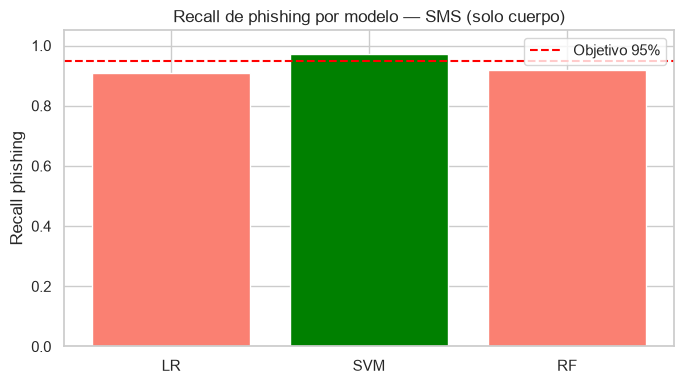

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
colors_sms = ["green" if v >= RECALL_TARGET else "salmon" for v in sms_results_df["recall_phishing"]]
ax.bar(sms_results_df["modelo"], sms_results_df["recall_phishing"], color=colors_sms)
ax.axhline(RECALL_TARGET, color="red", linestyle="--", label=f"Objetivo {RECALL_TARGET:.0%}")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall phishing")
ax.set_title("Recall de phishing por modelo — SMS (solo cuerpo)")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Validación con SpamSpa (generalización a SMS reales en español)

SpamSpa es un corpus de SMS spam en español (Apache 2.0) disponible en HuggingFace.
Validar el mejor modelo SMS contra este corpus permite estimar si los patrones
aprendidos en SpaPhish generalizan a mensajes cortos reales.

**Interpretación esperada:** métricas más bajas que en SpaPhish son normales
(distribución de dominios diferente). Lo relevante es si el recall de spam se mantiene
en un rango aceptable (≥ 80 %) o cae drásticamente, lo que indicaría sobreajuste al dominio email.

In [17]:
from datasets import load_dataset

spamspa_hf = load_dataset(
    "csv",
    data_files="hf://datasets/softecapps/spam_ham_spanish/train.csv",
    split="train",
)
spamspa_df = spamspa_hf.to_pandas()

print(f"SpamSpa cargado: {spamspa_df.shape}")
print(f"Columnas: {spamspa_df.columns.tolist()}")
print(f"Distribución de etiquetas:\n{spamspa_df.iloc[:, 1].value_counts()}")

# Detectar nombre de columnas de texto y etiqueta
text_col  = spamspa_df.columns[0]
label_col = spamspa_df.columns[1]

# Mapear ham→0, spam→1
label_map = {v: i for i, v in enumerate(["ham", "spam"])}
spamspa_df["label_bin"] = spamspa_df[label_col].map(label_map)
print(f"\nMapping de etiquetas: {label_map}")
print(f"Nulos tras mapeo: {spamspa_df['label_bin'].isna().sum()}")

# Anonimizar para coherencia con el training
spamspa_df["text_anon"] = spamspa_df[text_col].fillna("").apply(anonymize)

# Evaluar el mejor modelo SMS
best_sms_pipe = sms_pipelines[best_sms_name]

y_true = spamspa_df["label_bin"].dropna().astype(int)
y_pred = best_sms_pipe.predict(spamspa_df.loc[y_true.index, "text_anon"])

print(f"\n── SpamSpa × {best_sms_name} (SMS) ──")
print(classification_report(y_true, y_pred, target_names=["ham", "spam"]))

recall_spamspa = recall_score(y_true, y_pred, pos_label=1)
print(f"Recall spam: {recall_spamspa:.3f}  {'✓ ≥ 80%' if recall_spamspa >= 0.80 else '✗ < 80% — el modelo no generaliza bien a SMS'}")

Generating train split: 0 examples [00:00, ? examples/s]

SpamSpa cargado: (998, 2)
Columnas: ['mensaje', ' tipo']
Distribución de etiquetas:
 tipo
spam    521
ham     477
Name: count, dtype: int64

Mapping de etiquetas: {'ham': 0, 'spam': 1}
Nulos tras mapeo: 0

── SpamSpa × SVM (SMS) ──
              precision    recall  f1-score   support

         ham       0.43      0.36      0.40       477
        spam       0.49      0.56      0.53       521

    accuracy                           0.47       998
   macro avg       0.46      0.46      0.46       998
weighted avg       0.46      0.47      0.46       998

Recall spam: 0.564  ✗ < 80% — el modelo no generaliza bien a SMS


## 11.1. Experimento SMS mixto: SpaPhish + SpamSpa

Entrenamos los mismos tres clasificadores combinando el cuerpo de SpaPhish con
parte de SpamSpa (80 % de entrenamiento / 20 % de test, split estratificado).

El objetivo es ver cuánto mejora el recall en SMS reales sin sacrificar el recall
en el dominio email. Si el recall en SpamSpa test sube por encima del 80 % con
datos mixtos, el baseline TF-IDF podría ser suficiente como solución provisional
hasta que el fine-tuning NLP (#36) esté listo.

In [19]:
# Split SpamSpa 80/20 estratificado → hold-out limpio para evaluar generalización
spamspa_X_all = spamspa_df["text_anon"].reset_index(drop=True)
spamspa_y_all = spamspa_df["label_bin"].reset_index(drop=True)

spamspa_X_tr, spamspa_X_te, spamspa_y_tr, spamspa_y_te = train_test_split(
    spamspa_X_all, spamspa_y_all,
    test_size=0.20, random_state=RANDOM_STATE, stratify=spamspa_y_all,
)

# Combinar SpaPhish body train + SpamSpa train
X_mixed = pd.concat(
    [X_sms_train.reset_index(drop=True), spamspa_X_tr.reset_index(drop=True)],
    ignore_index=True,
)
y_mixed = pd.concat(
    [y_train.reset_index(drop=True), spamspa_y_tr.reset_index(drop=True)],
    ignore_index=True,
)

print(f"Mixed train: {len(X_mixed)} muestras")
print(f"  SpaPhish body: {len(X_sms_train)} | SpamSpa train: {len(spamspa_X_tr)}")
print(f"Distribución:\n{y_mixed.value_counts()}")

# Entrenar modelos mixtos (mismos hiperparámetros que el baseline)
mixed_pipelines = {
    name: Pipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, max_features=50_000)),
        ("clf",   clone(pipeline.named_steps["clf"])),
    ])
    for name, pipeline in pipelines.items()
}

mixed_results = []

for name, pipe in mixed_pipelines.items():
    pipe.fit(X_mixed, y_mixed)

    # ¿Mantiene recall en email?
    recall_email = recall_score(y_val, pipe.predict(X_sms_val), pos_label=1)
    # ¿Mejora recall en SMS reales?
    recall_sms   = recall_score(spamspa_y_te, pipe.predict(spamspa_X_te), pos_label=1)

    mixed_results.append({
        "modelo":            name,
        "recall_email":      recall_email,
        "recall_sms":        recall_sms,
        "cumple_email_95%":  recall_email >= RECALL_TARGET,
        "cumple_sms_80%":    recall_sms >= 0.80,
    })
    print(f"\n── {name} (mixto) ──")
    print(f"  Recall phishing SpaPhish val : {recall_email:.3f}")
    print(f"  Recall spam     SpamSpa test : {recall_sms:.3f}")

mixed_df = pd.DataFrame(mixed_results)
display(mixed_df.round(3))

best_mixed = mixed_df.sort_values("recall_sms", ascending=False).iloc[0]["modelo"]
print(f"\nMejor modelo mixto (por recall SMS): {best_mixed}")

Mixed train: 1773 muestras
  SpaPhish body: 975 | SpamSpa train: 798
Distribución:
1    927
0    846
Name: count, dtype: int64

── LR (mixto) ──
  Recall phishing SpaPhish val : 0.909
  Recall spam     SpamSpa test : 0.913

── SVM (mixto) ──
  Recall phishing SpaPhish val : 0.936
  Recall spam     SpamSpa test : 0.913

── RF (mixto) ──
  Recall phishing SpaPhish val : 0.900
  Recall spam     SpamSpa test : 0.923


,modelo,recall_email,recall_sms,cumple_email_95%,cumple_sms_80%
0,LR,0.909,0.913,False,True
1,SVM,0.936,0.913,False,True
2,RF,0.900,0.923,False,True



Mejor modelo mixto (por recall SMS): RF


## 12. Conclusiones

**Email baseline (asunto + cuerpo) — validación SpaPhish:**

| Modelo | Recall phishing | F1 phishing | Cumple ≥95% |
|--------|----------------|-------------|-------------|
| LR     | 0.909          | 0.935       | No          |
| SVM    | **0.973**      | **0.977**   | **Sí**      |
| RF     | 0.955          | 0.913       | Sí          |

**Email test (SVM):** recall 0.95 · precision 0.99 · F1 0.97 · accuracy 0.97

---

**SMS baseline (solo cuerpo SpaPhish) — validación:**

| Modelo | Recall phishing | Recall spam SpamSpa | Cumple email ≥95% | Cumple SMS ≥80% |
|--------|----------------|---------------------|-------------------|-----------------|
| LR     | 0.909          | 0.564               | No                | No              |
| SVM    | **0.973**      | 0.564               | **Sí**            | No              |
| RF     | 0.955          | 0.564               | Sí                | No              |

---

**SMS mixto (SpaPhish + SpamSpa) — 1773 muestras de entrenamiento:**

| Modelo | Recall email | Recall SMS | Cumple email ≥95% | Cumple SMS ≥80% |
|--------|-------------|------------|-------------------|-----------------|
| LR     | 0.909       | 0.913      | No                | **Sí**          |
| SVM    | 0.936       | 0.913      | No                | **Sí**          |
| RF     | 0.900       | **0.923**  | No                | **Sí**          |

---

**Análisis del tradeoff:**

Añadir SpamSpa al entrenamiento sube el recall en SMS de 0.564 → 0.913–0.923 (supera el umbral del 80 %), pero ningún modelo mantiene el recall de email ≥ 95 %. El mejor compromiso puro-email (SVM 0.973) y el mejor SMS (RF mixto 0.923) no coexisten en el mismo modelo TF-IDF: optimizar un dominio sacrifica el otro.

**Conclusión principal:** el baseline TF-IDF tiene un límite estructural — no puede optimizar simultáneamente email y SMS con un solo vocabulario. El fine-tuning NLP (#36) es necesario para producción.

**Recomendaciones para el modelo fine-tuned (#36):**
- Usar `dccuchile/bert-base-spanish-wwm-cased` (BETO) o `PlanTL-GOB-ES/roberta-base-bne`.
- Entrenar con SpaPhish + SpamSpa desde el inicio.
- Objetivo: recall ≥ 95 % en SpaPhish test **y** ≥ 80 % en SpamSpa test simultáneamente.
- El cuerpo es el único campo relevante para SMS; el asunto puede ignorarse.